# 05 · Stage 3 data scaling (500 / 1000 / 2000)


**Owner:** member B · **GPU:** ≈ 3–5 h · **Needs:** decisions `best_model`, `best_res` (notebook 04) · **Parallel with:** 06, 07

Best model at best resolution trained on the nested subsets; the 1000-image point is reused from S1/S2. The epoch budget
is fixed (same number of epochs), so larger subsets also get proportionally more iterations — the standard data-scaling protocol.
The 500 and 2000 runs double as rows C and D of the final ablation.

In [2]:
# ===== 0. Setup — identical in every notebook. Runtime > Change runtime type > T4 GPU =====
SMOKE_TEST = False   # True: 16 train / 8 val images, 1 epoch — checks the whole pipeline in minutes
DRIVE_ROOT = "/content/drive/MyDrive/MAVREC"   # shared team folder (each member: "Add shortcut to Drive")

import os, sys, subprocess, importlib
try:
    from google.colab import drive
    try:
        os.listdir("/content/drive/MyDrive")   # raises if the Drive FUSE mount went stale
        drive.mount("/content/drive")
    except OSError:  # "Transport endpoint is not connected" after a Drive hiccup: remount
        drive.mount("/content/drive", force_remount=True)
except ImportError:
    print("Not in Colab — make sure DRIVE_ROOT exists locally.")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.173", "transformers==5.18.0", "pycocotools>=2.0.8", "timm>=1.0.15", "tabulate", "tensorboard", "seaborn"], check=True)

CODE_DIR = os.path.join(DRIVE_ROOT, "Final_Project_Code")
assert os.path.exists(os.path.join(CODE_DIR, "mavrec_lib.py")), "Run 00_Setup_and_Data_Preparation first (it installs mavrec_lib.py)."
sys.path.insert(0, CODE_DIR)
import mavrec_lib as ml; importlib.reload(ml)
CFG = ml.setup(DRIVE_ROOT, smoke=SMOKE_TEST or None)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
N_SMALL, N_SCREEN, N_LARGE = ml.TRAIN_SIZES      # 500, 1000, 2000

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Environment:
  python       : 3.13.15
  torch        : 2.11.0+cu130
  cuda         : True
  torchvision  : 0.26.0+cu130
  ultralytics  : 8.4.173
  transformers : 5.18.0
  pycocotools  : 2.0.11
  numpy        : 2.1.3
  lib          : 1.0.0
  gpu          : Tesla T4
  gpu_mem_gb   : 14.6


In [3]:
BEST_MODEL = ml.get_decision("best_model", required=True)
BEST_RES = ml.get_decision("best_res", required=True)
FINALISTS = ml.get_decision("finalists", [BEST_MODEL])
print(BEST_MODEL, BEST_RES, FINALISTS)

yolov8m 1280 ['yolov8m', 'frcnn_r50_v2']


### Essential: best model at 500 and 2000

In [4]:
for n in (N_SMALL, N_LARGE):
    ml.run_experiment(ml.make_spec(BEST_MODEL, f"aerial_train_{n}", BEST_RES, stage="S3"))

[S3_yolov8m_n500_r1280_full_COCO_s42] done — skipping (force=True to redo)
Pack 'aerial_1280' unpacked to local disk in 35s
[S3_yolov8m_n2000_r1280_full_COCO_s42] training yolov8m | data=aerial_train_2000 | res=1280 | epochs=40 | batch=4 | init=coco
Resuming from /content/drive/MyDrive/MAVREC/Final_Project_Results/runs/S3_yolov8m_n2000_r1280_full_COCO_s42/train/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/mavrec_local/yolo/aerial_train_2000__aerial_val__aerial_1280/data.yaml, degrees=0.0, determini

### Optional: second finalist (tests whether the ranking changes with more data — e.g. transformers are often more data-hungry)

In [5]:
RUN_SECOND = False
if RUN_SECOND and len(FINALISTS) > 1:
    for n in (N_SMALL, N_LARGE):
        ml.run_experiment(ml.make_spec(FINALISTS[1], f"aerial_train_{n}", BEST_RES, stage="S3"))

,experiment_id,stage,model_version,dataset_size,resolution,tiling,inference_mode,pretraining,mAP50_95,mAP50,APS,APt,APM,recall,F1,FPS,GPU_memory_infer_GB,parameters_M,train_time_h
14,S2_frcnn_r50_v2_n1000_r1280_full_COCO_s42,S2,frcnn_r50_v2,1000,1280.0,none,full,COCO,56.867,82.768,44.145,22.302,56.109,89.862,92.282,13.20,0.57,43.30,1.549
20,S3_yolov8m_n500_r1280_full_COCO_s42,S3,yolov8m,500,1280.0,none,full,COCO,63.086,89.694,34.456,12.670,61.416,86.097,89.261,25.63,0.15,25.86,0.716
16,S2_yolov8m_n1000_r1280_full_COCO_s42,S2,yolov8m,1000,1280.0,none,full,COCO,66.873,91.441,38.394,16.537,66.810,89.438,90.852,30.31,0.15,25.86,1.531
19,S3_yolov8m_n2000_r1280_full_COCO_s42,S3,yolov8m,2000,1280.0,none,full,COCO,70.811,92.674,43.506,18.202,72.938,91.187,92.699,30.34,0.15,25.86,0.739


saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/S3_data_scaling.csv
saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/S3_data_scaling.png


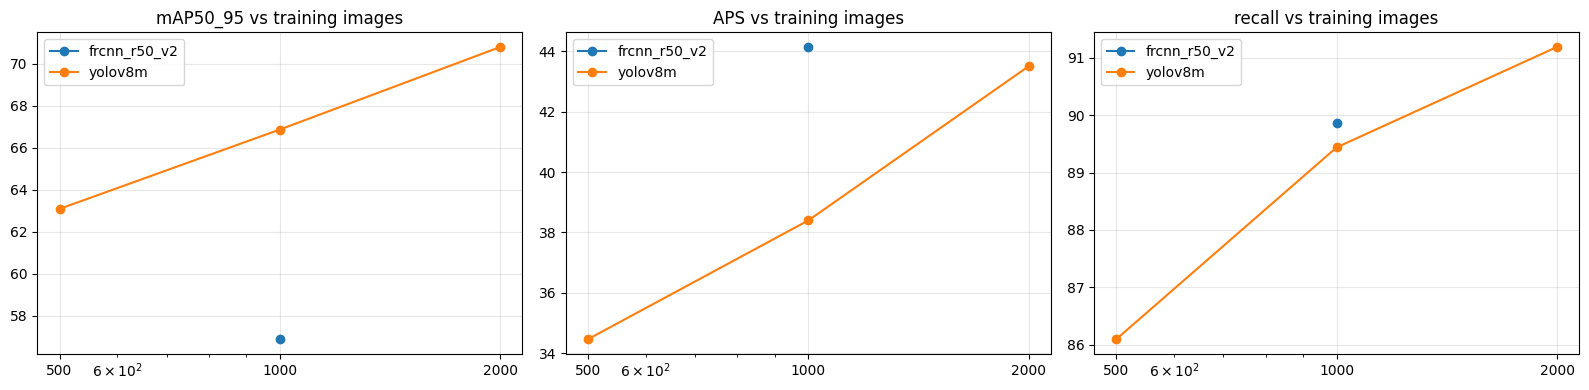

yolov8m: +3.86 mAP50-95 per doubling of training data (log-linear fit, 3 points)
DECISION scaling_gain_per_doubling = 3.86


In [6]:
df = ml.results_df()
S = df[df.model_version.isin(FINALISTS) & (df.resolution == BEST_RES) & (df.tiling == "none") & (df.pretraining == "COCO") &
       df.stage.isin(["S1", "S2", "S3"]) & (df.eval_split == "val") & (df.inference_mode == "full")].sort_values(["model_version", "dataset_size"])
display(S[["experiment_id","stage","model_version","dataset_size","resolution","tiling","inference_mode","pretraining","mAP50_95","mAP50","APS","APt","APM","recall","F1","FPS","GPU_memory_infer_GB","parameters_M","train_time_h"]])
ml.save_table(S[["experiment_id","stage","model_version","dataset_size","resolution","tiling","inference_mode","pretraining","mAP50_95","mAP50","APS","APt","APM","recall","F1","FPS","GPU_memory_infer_GB","parameters_M","train_time_h"]], "S3_data_scaling")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for m, g in S.groupby("model_version"):
    for a, met in zip(ax, ["mAP50_95", "APS", "recall"]):
        a.plot(g.dataset_size, g[met], "o-", label=m); a.set_xscale("log"); a.set_xticks(list(ml.TRAIN_SIZES)); a.set_xticklabels(ml.TRAIN_SIZES); a.set_title(met + " vs training images")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); ml.savefig("S3_data_scaling.png"); plt.show()
g = S[S.model_version == BEST_MODEL].sort_values("dataset_size")
if len(g) >= 2:
    slope = np.polyfit(np.log2(g.dataset_size.astype(float)), g.mAP50_95.astype(float), 1)[0]
    print(f"{BEST_MODEL}: +{slope:.2f} mAP50-95 per doubling of training data (log-linear fit, {len(g)} points)")
    ml.set_decision("scaling_gain_per_doubling", round(float(slope), 2), "log-linear fit over 500/1000/2000")

Interpretation guide: if the curve is still rising at 2000 the model is data-limited (report the slope and note the full 8,605-frame set as future work); if it has flattened, extra annotation effort is better spent elsewhere.